<a href="https://colab.research.google.com/github/ixchelalvaradoz24-dot/AF3_PENDULO_ROBOT_CODE/blob/main/C%C3%B3digo_AF3_MSDSM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

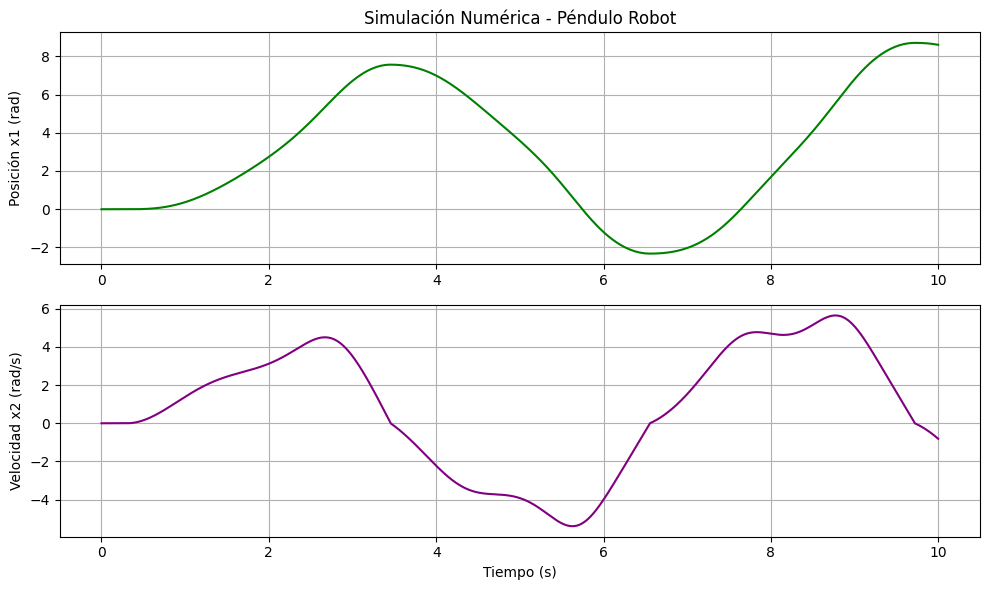

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Parámetros del sistema ----------
Inercia_r = 0.16
masa      = 5
gravedad  = 9.81
dist_cm   = 0.01
viscosidad= 0.14
fric_coul = 0.45
par_motor = 0.8        # Par del motor (N·m)

# Inercia equivalente respecto al pivote
Inercia_total = Inercia_r

# ---------- Configuración de la simulación ----------
paso_t = 0.001         # Paso de tiempo (s)
tiempo_total = 10      # Tiempo total (s)
total_pasos  = int(tiempo_total / paso_t)

# Arreglos de almacenamiento (historial)
t  = np.zeros(total_pasos)
x1 = np.zeros(total_pasos) # Posición (rad)
x2 = np.zeros(total_pasos) # Velocidad (rad/s)
# Condiciones iniciales: x1[0] = 0 y x2[0] = 0 por defecto en ceros

# ---------- Bucle de Simulación numérica (Euler) ----------
for k in range(total_pasos - 1):
    # El par se puede mantener constante o calcularse dinámicamente:
    tau = 1.5 * np.sin(t[k])

    # Ecuación diferencial corregida en espacio de estados
    x2_punto = (tau - (masa * gravedad * dist_cm * np.sin(x1[k])) - (viscosidad * x2[k]) - (fric_coul * np.sign(x2[k]))) / Inercia_total

    # Métodos de integración de Euler para la posición y velocidad
    x1[k+1] = x1[k] + (x2[k] * paso_t)
    x2[k+1] = x2[k] + (x2_punto * paso_t)
    t[k+1]  = t[k] + paso_t

# ---------- Gráficas de Resultados ----------
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t, x1, color='green', linewidth=1.5)
plt.ylabel("Posición x1 (rad)")
plt.title("Simulación Numérica - Péndulo Robot")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, x2, color='purple', linewidth=1.5)
plt.ylabel("Velocidad x2 (rad/s)")
plt.xlabel("Tiempo (s)")
plt.grid(True)

plt.tight_layout()
plt.show()